# Phase 4 — 2023 Bay Area exploratory analysis

Historical observed records, not current hiring. Source: Luke Barousse data_jobs, pinned release; see `docs/data_attribution.md`. Source, nine-county definition, role rules and SQLite schema remain unchanged. Nothing is downloaded or published.

## 1. Verify the database and reconcile SQL with Python
The runner uses read-only SQLite, validates Phase 3 provenance/content, executes named SQL queries, independently recomputes all nine tables in pandas and checks plotted values. Raw-directory reads stalled, so raw acquisition integrity is recorded Phase 3 evidence rather than a fresh raw hash.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'config/phase3_rules.json').exists(), 'Run inside the project.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Python:', sys.version.split()[0])

Python: 3.12.7


In [2]:
from src.run_analysis import run
# This creates Phase 4 analysis reports/figures only, never ETL or a dashboard.
result = run(ROOT)
tables = {name: pd.DataFrame(rows) for name, rows in result['tables'].items()}
assert len(result['reconciliation']) == 9
assert all(item['status'] == 'matched' for item in result['reconciliation'].values())
display(pd.DataFrame(result['reconciliation']).T)
print('Result checksum:', result['result_sha256'])

Matplotlib is building the font cache; this may take a moment.


,status,rows,columns
cohort_audit,matched,4,3
role_summary,matched,4,16
skill_by_role,matched,780,10
geography_by_role,matched,243,10
county_by_role,matched,32,4
geography_coverage,matched,1,7
seniority_by_role,matched,23,5
locality_skill_by_role,matched,5495,11
skill_count_summary,matched,4,8


Result checksum: 9e42eafc1394eaa59990c7504c2f0ebc4255e4f2d7c63f38e9dc1b5c8e7ac632


## 2. Define the cohort before examining patterns
Only accepted title-only target roles enter analytical denominators. Ambiguous/unclassified/non-target rows remain visible here. Record counts do not certify unique vacancies.

,role_status,records,retained_share_pct
0,accepted_title_only,12631,77.858596
1,ambiguous,209,1.288294
2,out_of_scope,280,1.725945
3,unclassified,3103,19.127165


,role,records,cohort_share_pct,usable_tag_records,missing_tag_records,empty_tag_records,malformed_tag_records,tag_coverage_pct,derived_annual_present,derived_hourly_present,derived_annual_coverage_pct,verified_advertised_salary_records,explicit_seniority_records,unknown_seniority_records,conflicting_seniority_records,unknown_arrangement_records
0,Data Analyst,4829,38.231336,4093,736,0,0,84.758749,304,296,6.295299,0,1342,3485,2,4829
1,Data Engineer,2035,16.111155,1928,107,0,0,94.742015,221,119,10.859951,0,825,1209,1,2035
2,Data Scientist,5700,45.127068,5019,681,0,0,88.052632,645,150,11.315789,0,2693,2997,10,5700
3,Machine Learning Engineer,67,0.530441,61,6,0,0,91.044776,22,2,32.835821,0,36,31,0,67


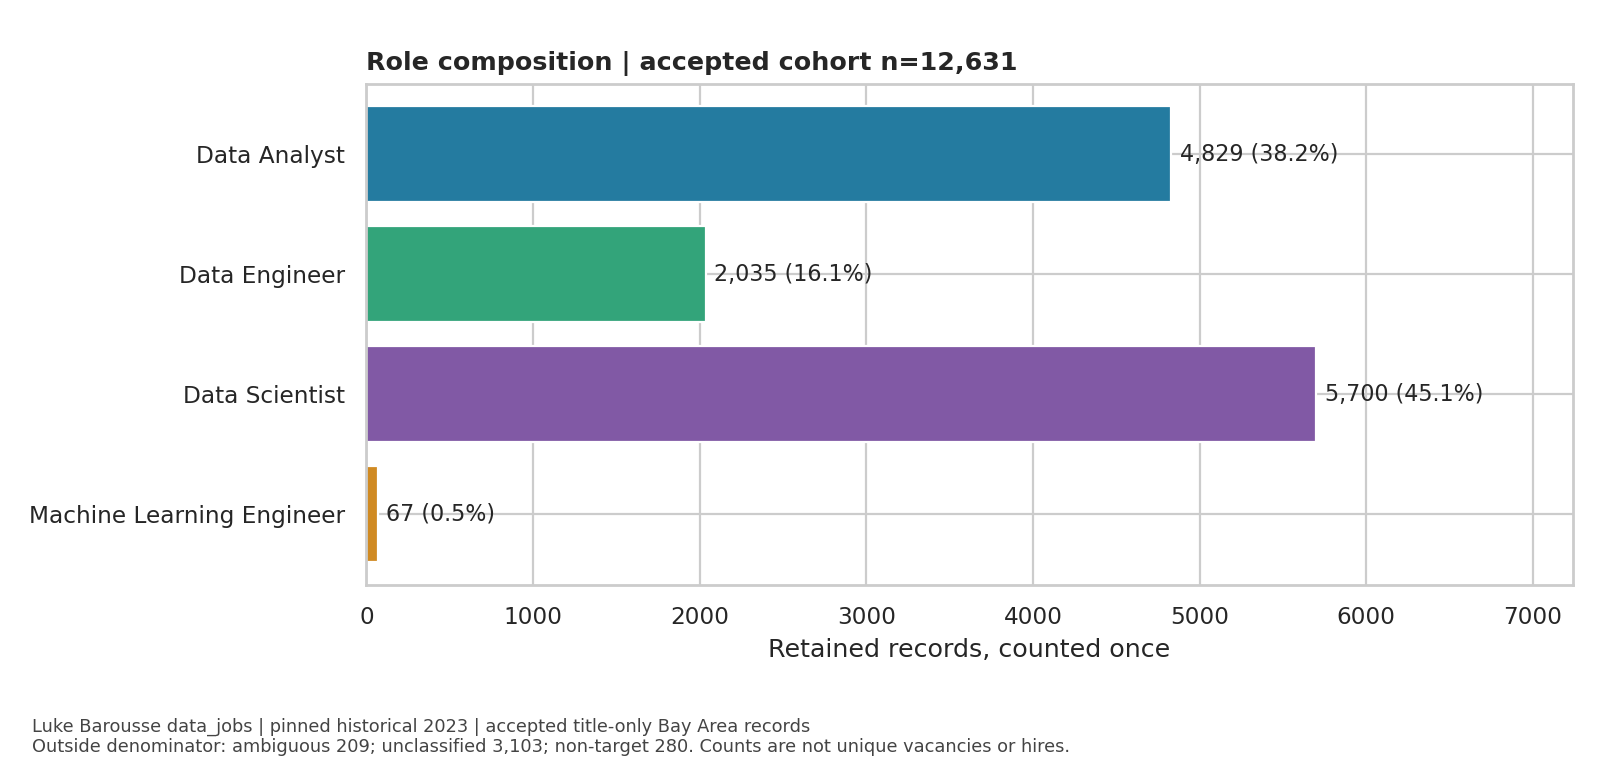

In [3]:
display(tables['cohort_audit'])
display(tables['role_summary'])
display(Image(filename=str(ROOT/'reports/figures/phase4_role_composition.png')))

## 3. Skills and field coverage
Skill rates use populated inherited lists, not all records or missing descriptions. Rates can sum over 100%. Missing lists are not evidence of absent requirements; salary field presence does not establish comparable pay.

,role,skill,tagged_records,usable_tag_records,role_records,comparison_pct
157,Data Analyst,sql,2879,4093,4829,70.339604
166,Data Analyst,tableau,1898,4093,4829,46.371854
125,Data Analyst,python,1853,4093,4829,45.272416
48,Data Analyst,excel,1492,4093,4829,36.452480
128,Data Analyst,r,1139,4093,4829,27.827999
119,Data Analyst,power bi,563,4093,4829,13.755192
320,Data Engineer,python,1461,1928,2035,75.778008
352,Data Engineer,sql,1334,1928,2035,69.190871
347,Data Engineer,spark,796,1928,2035,41.286307
206,Data Engineer,aws,792,1928,2035,41.078838


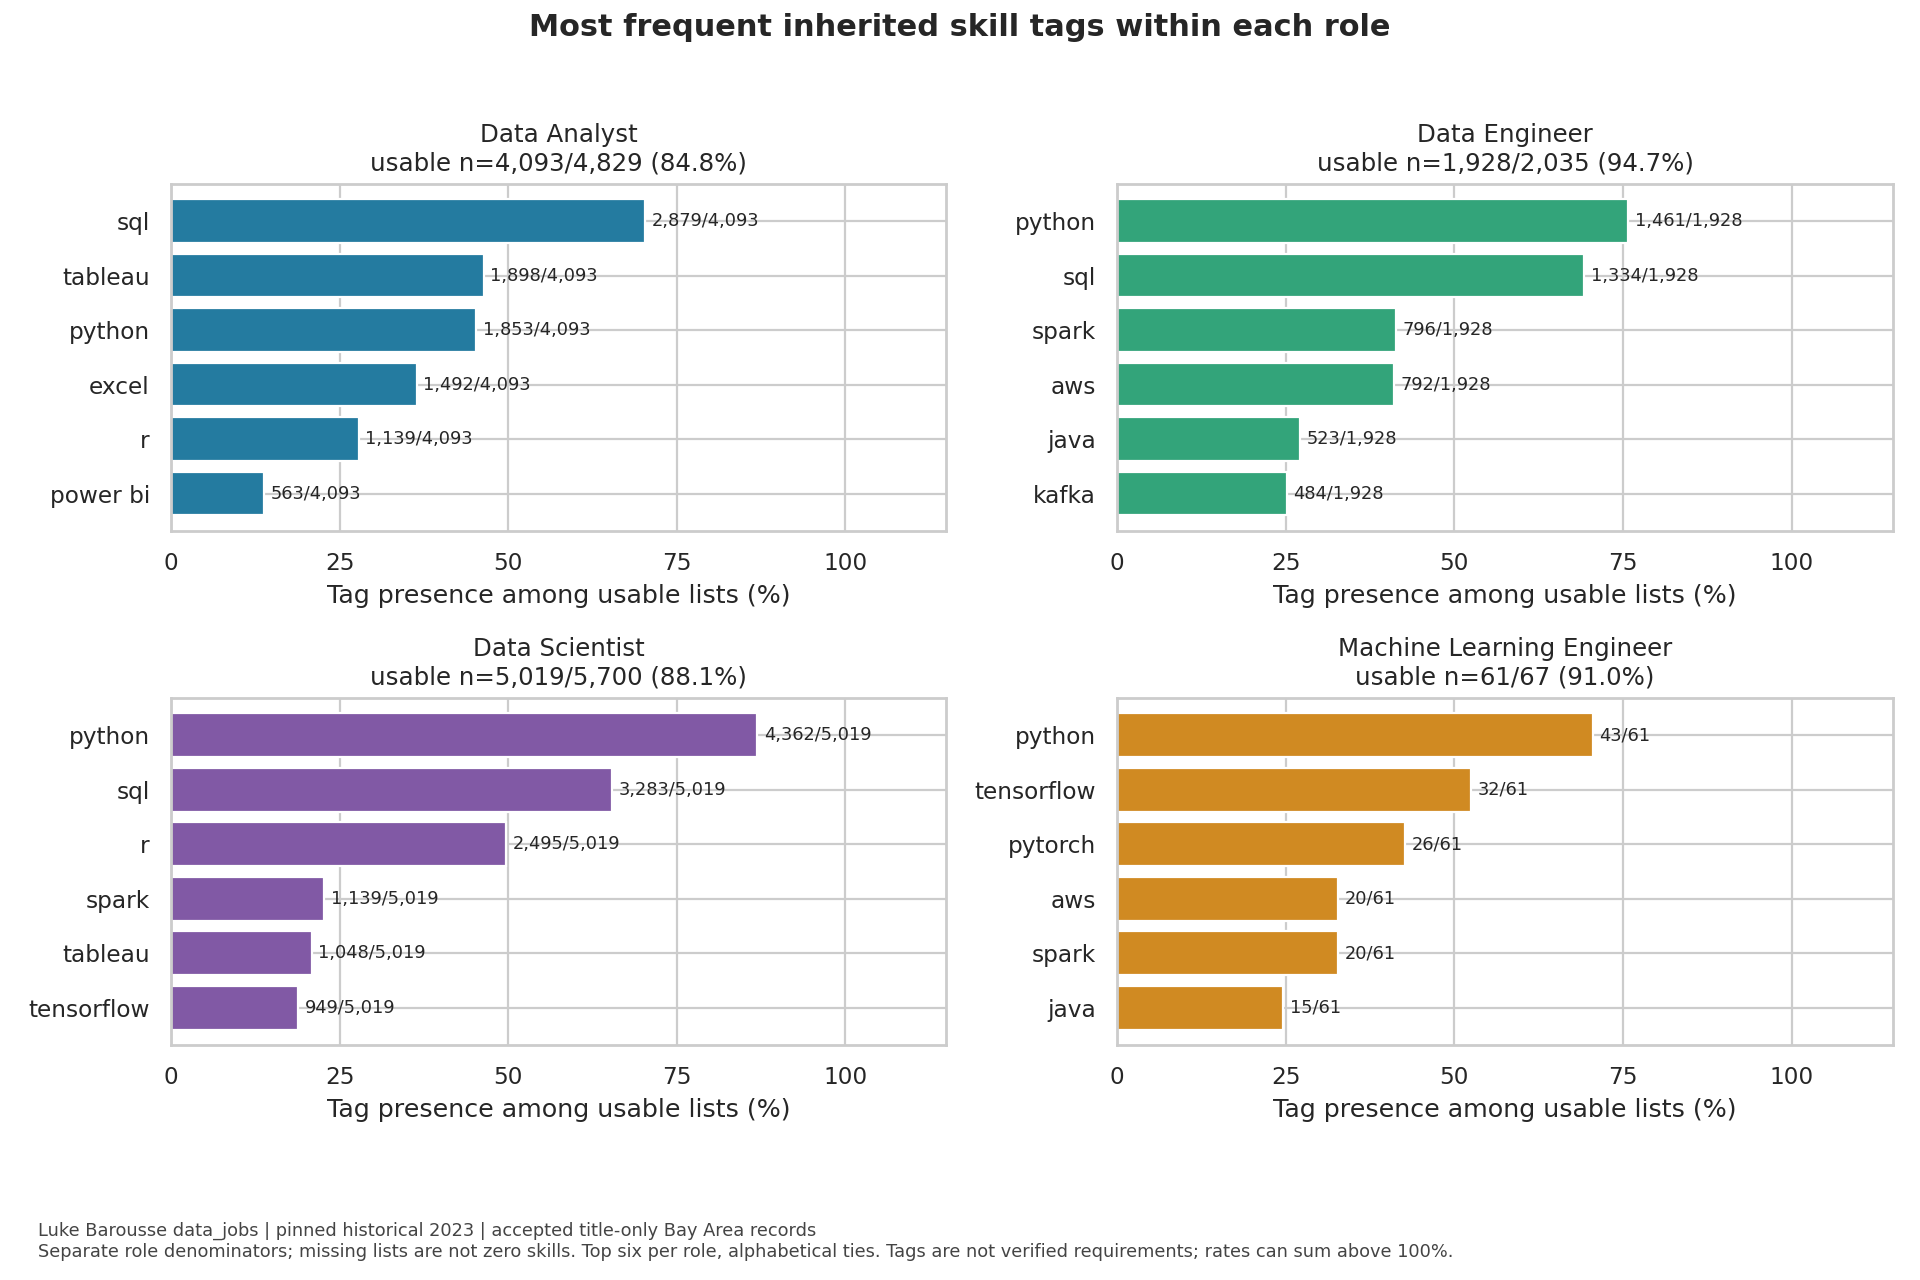

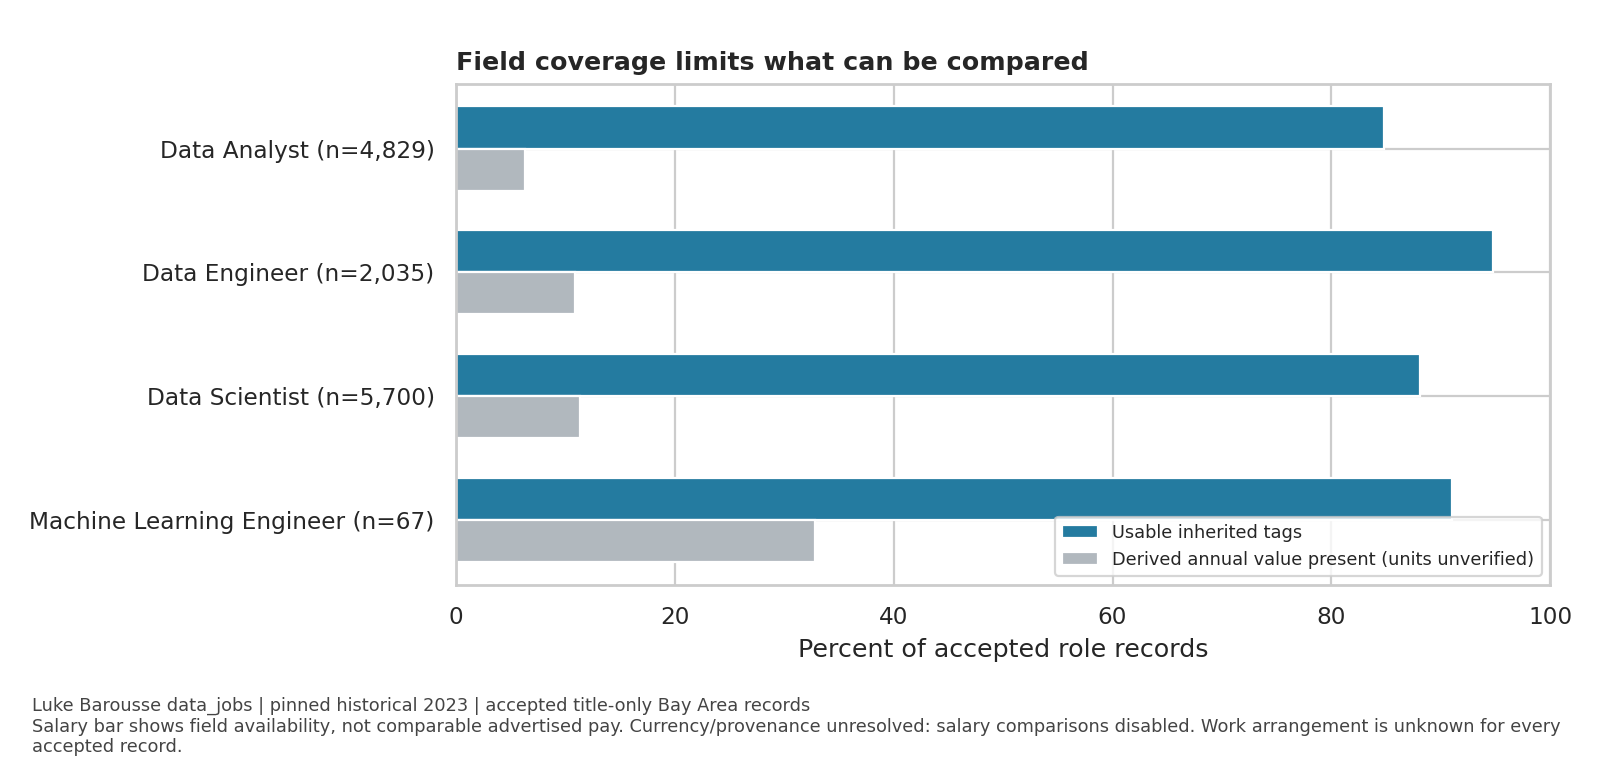

In [4]:
skills=tables['skill_by_role']
top=(skills.loc[skills.comparison_allowed.eq(1) & skills.tagged_records.gt(0)]
     .sort_values(['role','tagged_records','skill'],ascending=[True,False,True])
     .groupby('role').head(6))
display(top[['role','skill','tagged_records','usable_tag_records','role_records','comparison_pct']])
for name in ['phase4_skill_profile','phase4_coverage']:
    display(Image(filename=str(ROOT/'reports/figures'/(name+'.png'))))

## 4. Geography, role mix and skills within cities
COUNT(DISTINCT record ID) protects against many-to-many join inflation. City/county memberships remain non-additive. Communities and county-only evidence are retained separately. Sparse skill comparisons require at least 10 usable lists.

,cohort_records,multi_bay_location_records,records_with_city,records_with_community,county_only_records,bay_location_memberships,bay_county_memberships
0,12631,0,12366,265,0,12631,12631


,location_role_cells,memberships
location_precision,,
city,216,12366
community,27,265


,locality,role,records,city_denominator,within_city_role_pct
0,San Francisco,Data Analyst,1233,3450,35.739130
1,San Francisco,Data Engineer,567,3450,16.434783
2,San Francisco,Data Scientist,1625,3450,47.101449
3,San Francisco,Machine Learning Engineer,25,3450,0.724638
42,San Jose,Data Analyst,561,1248,44.951923
43,San Jose,Data Engineer,204,1248,16.346154
44,San Jose,Data Scientist,479,1248,38.381410
45,San Jose,Machine Learning Engineer,4,1248,0.320513


,location_id,locality,county,location_precision,role,skill,tagged_records,role_location_records,usable_tag_records,comparison_pct,comparison_allowed
97,1,San Francisco,San Francisco,city,Data Analyst,sql,851,1233,1113,76.460018,1
73,1,San Francisco,San Francisco,city,Data Analyst,python,515,1233,1113,46.271339,1
103,1,San Francisco,San Francisco,city,Data Analyst,tableau,515,1233,1113,46.271339,1
76,1,San Francisco,San Francisco,city,Data Analyst,r,386,1233,1113,34.681042,1
23,1,San Francisco,San Francisco,city,Data Analyst,excel,379,1233,1113,34.052111,1
2194,12,San Jose,Santa Clara,city,Data Analyst,sql,374,561,494,75.708502,1
2199,12,San Jose,Santa Clara,city,Data Analyst,tableau,289,561,494,58.502024,1
2175,12,San Jose,Santa Clara,city,Data Analyst,python,223,561,494,45.141700,1
2138,12,San Jose,Santa Clara,city,Data Analyst,excel,210,561,494,42.510121,1
2177,12,San Jose,Santa Clara,city,Data Analyst,r,116,561,494,23.481781,1


Locality-role cells with fewer than 10 records: 147 of 243


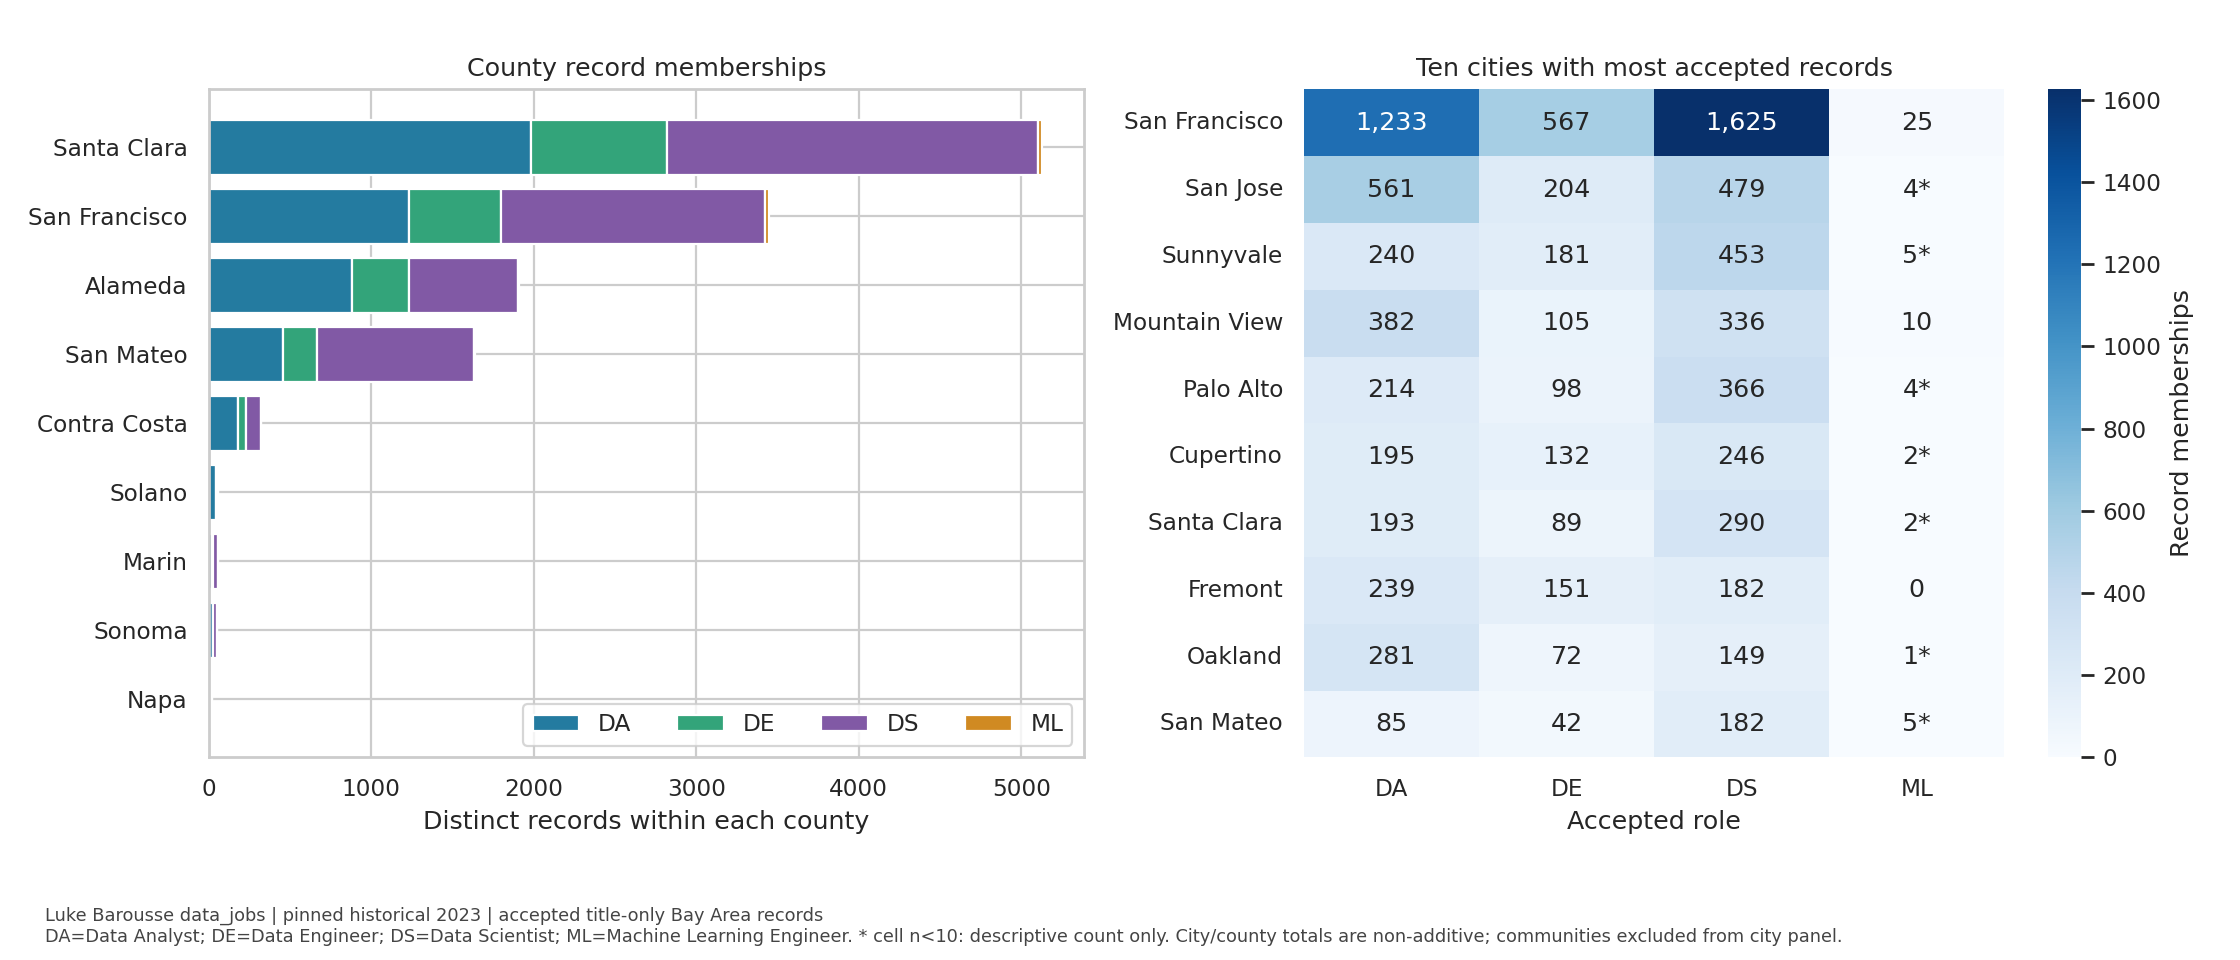

In [5]:
display(tables['geography_coverage'])
geo=tables['geography_by_role']
display(geo.groupby('location_precision').agg(location_role_cells=('records','size'),memberships=('records','sum')))
# Sum across disjoint roles WITHIN each location, never across overlapping cities.
major=geo.loc[geo.location_precision.eq('city') & geo.locality.isin(['San Francisco','San Jose'])].copy()
major['city_denominator']=major.groupby('location_id').records.transform('sum')
major['within_city_role_pct']=100*major.records/major.city_denominator
display(major[['locality','role','records','city_denominator','within_city_role_pct']])
local=tables['locality_skill_by_role']
local=local.loc[local.location_precision.eq('city') & local.locality.isin(['San Francisco','San Jose']) & local.role.eq('Data Analyst') & local.comparison_allowed.eq(1)]
display(local.sort_values(['locality','tagged_records','skill'],ascending=[True,False,True]).groupby('locality').head(5))
print('Locality-role cells with fewer than 10 records:',int(geo.small_group.sum()),'of',len(geo))
display(Image(filename=str(ROOT/'reports/figures/phase4_geography.png')))

## 5. Explicit seniority
Unknown stays unknown; absence of a senior term does not establish entry level. Entry/junior includes interns. Numeric levels and required experience are not inferred.

,role,seniority,records,role_share_pct,small_group
0,Data Analyst,entry/junior,239,4.949265,0
1,Data Analyst,lead/staff/principal,240,4.969973,0
2,Data Analyst,management,19,0.393456,0
3,Data Analyst,mid,1,0.020708,1
4,Data Analyst,mixed/conflicting,2,0.041416,1
5,Data Analyst,senior,843,17.457030,0
6,Data Analyst,unknown,3485,72.168151,0
7,Data Engineer,entry/junior,24,1.179361,0
8,Data Engineer,lead/staff/principal,230,11.302211,0
9,Data Engineer,management,5,0.245700,1


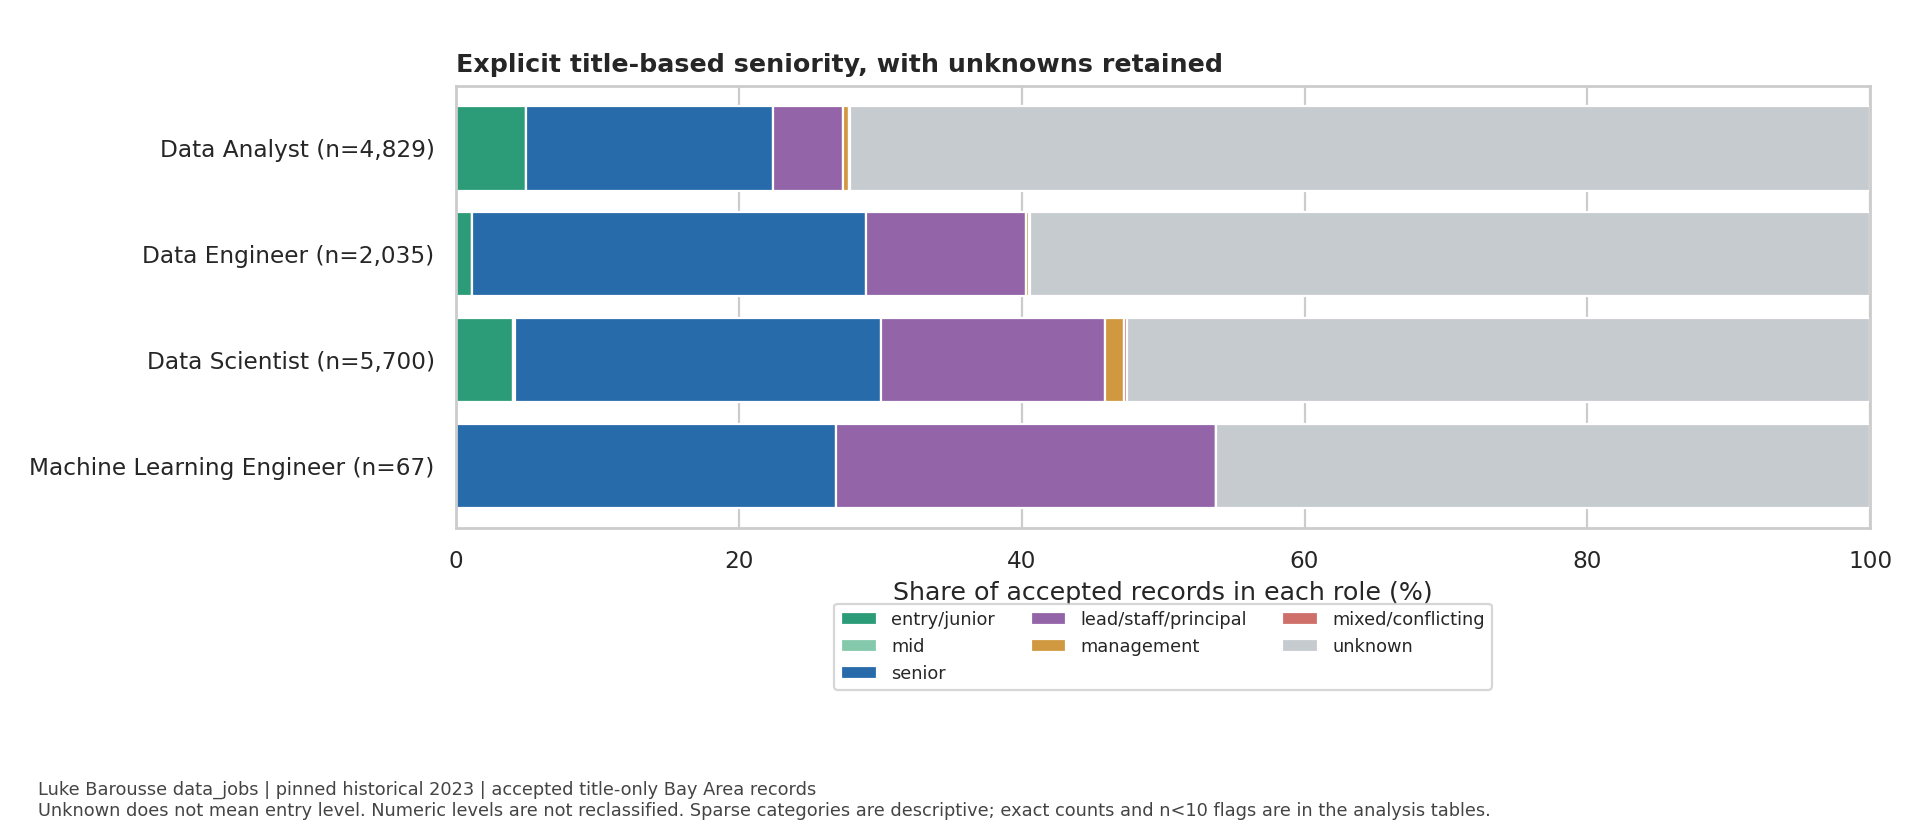

In [6]:
display(tables['seniority_by_role'])
display(Image(filename=str(ROOT/'reports/figures/phase4_seniority.png')))

## 6. Questions deliberately left unanswered
No salary amounts/comparisons, hiring/posting trends or arrangement shares are enabled. These limitations are part of the findings, not gaps filled by assumptions.

In [7]:
assert tables['role_summary'].verified_advertised_salary_records.sum() == 0
print('Disabled metrics:', result['disabled_metrics'])
display(Markdown((ROOT/'reports/phase4_findings.md').read_text()))

Disabled metrics: ['salary_amounts_and_comparisons', 'posting_and_hiring_trends', 'explicit_work_arrangement_shares', 'original_text_skill_requirements']


# Phase 4 findings — historical observed Bay Area records

Completed 2026-10-27. Phase 4 only; Phase 5 has not started. Source: Luke Barousse data_jobs, pinned 2023 release. [Attribution and license](../docs/data_attribution.md). Figures and results remain local/unpublished.

## Questions answered and methods

We describe accepted records by role, inherited skill tags, resolved geography and explicit title-based seniority. SQL is the measurement source; independently constructed pandas summaries reconcile all nine result tables. Distinct record IDs prevent skill/location joins from multiplying the cohort. Source/rule/schema identity is unchanged.

Role and seniority shares use all accepted records. Skill rates use populated inherited lists within the selected role/location; missing lists are not negatives. Comparisons with fewer than 10 usable lists are suppressed, while counts remain visible. Tag-count summaries use mean, median, linear-interpolated quartiles and range. Percentage-point contrasts are descriptive, unadjusted for seniority/employer mix. No p-values, confidence intervals, population estimates or causal tests are justified by this non-random, potentially dependent/reposted source.

## 1. Role composition and visible classification uncertainty

Accepted cohort: **12,631 / 16,223 retained Bay records (77.9%)**. Outside the denominator: ambiguous **209**; unclassified **3,103**; explicit non-target **280**. These are not silently dropped from the audit.

| Accepted role | Records n | Cohort share % | Usable tags n | Tag coverage % |
| --- | --- | --- | --- | --- |
| Data Analyst | 4,829 | 38.2 | 4,093 | 84.8 |
| Data Engineer | 2,035 | 16.1 | 1,928 | 94.7 |
| Data Scientist | 5,700 | 45.1 | 5,019 | 88.1 |
| Machine Learning Engineer | 67 | 0.5 | 61 | 91.0 |

Data Scientist has the largest accepted record count. The Machine Learning Engineer cohort is much smaller; the strict title rule and excluded mixed-role titles affect that count. These are sample composition differences, not market-wide role demand or hires.

## 2. Technical skill tags and missingness

Usable inherited lists: **11,101/12,631 (87.9%)**; missing lists: **1,530**; empty/malformed: **0**. Original descriptions are unavailable for all records, so full-text coverage is unavailable and required/preferred skill distinctions cannot be assessed.

- Data Analyst: sql 2,879/4,093 (70.3%), tableau 1,898/4,093 (46.4%), python 1,853/4,093 (45.3%)
- Data Engineer: python 1,461/1,928 (75.8%), sql 1,334/1,928 (69.2%), spark 796/1,928 (41.3%)
- Data Scientist: python 4,362/5,019 (86.9%), sql 3,283/5,019 (65.4%), r 2,495/5,019 (49.7%)
- Machine Learning Engineer: python 43/61 (70.5%), tensorflow 32/61 (52.5%), pytorch 26/61 (42.6%)

These rates are conditional on usable lists; they can sum above 100% because a record has multiple tags. Tags are inherited publisher output, not independently validated employer requirements. Missingness can differ by role.

| Role | Usable n | Mean tags | Q1 | Median | Q3 | Min | Max |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Data Analyst | 4,093 | 4.2 | 2.0 | 4.0 | 5.0 | 1 | 18 |
| Data Engineer | 1,928 | 7.1 | 4.0 | 7.0 | 9.0 | 1 | 24 |
| Data Scientist | 5,019 | 5.3 | 3.0 | 5.0 | 7.0 | 1 | 24 |
| Machine Learning Engineer | 61 | 5.9 | 3.0 | 5.0 | 7.0 | 1 | 14 |

Illustrative within-sample percentage-point contrasts (first role minus second):

| Tag | First role | Second role | First usable n | Second usable n | Difference pp |
| --- | --- | --- | --- | --- | --- |
| python | Data Scientist | Data Engineer | 5,019 | 1,928 | 11.1 |
| sql | Data Analyst | Data Engineer | 4,093 | 1,928 | 1.1 |
| tableau | Data Analyst | Data Scientist | 4,093 | 5,019 | 25.5 |

| Tag contrast | Logical difference lower pp | Logical difference upper pp |
| --- | --- | --- |
| python | -0.5 | 16.7 |
| sql | -11.2 | 9.3 |
| tableau | 9.0 | 36.2 |

These difference ranges allow unavailable-list content to vary separately in each role. If a range includes zero, even the direction of the all-record tag gap is not fixed by observed lists. A range staying positive still does not establish a causal/population result or protect against extraction errors.

The sensitivity figure treats each unavailable list as either lacking or containing a selected tag: lower = tagged/all role records; upper = (tagged + unavailable)/all role records. These are logical missing-data bounds, not confidence intervals, imputed values or bounds on true requirements; extraction errors remain outside the calculation.

## 3. Geography and role/skill differences

The largest accepted city association is **San Francisco: 3,450 (27.3% of the accepted cohort)**. The largest county association is **Santa Clara: 5,130**.

| Incorporated city | Accepted record memberships |
| --- | --- |
| San Francisco | 3,450 |
| San Jose | 1,248 |
| Sunnyvale | 879 |
| Mountain View | 833 |
| Palo Alto | 682 |

Role mix in two major cities (within-city denominators, counts are not skills-expanded):

| City | Role | Role n | City n | Within-city role % |
| --- | --- | --- | --- | --- |
| San Francisco | Data Analyst | 1,233 | 3,450 | 35.7 |
| San Francisco | Data Engineer | 567 | 3,450 | 16.4 |
| San Francisco | Data Scientist | 1,625 | 3,450 | 47.1 |
| San Francisco | Machine Learning Engineer | 25 | 3,450 | 0.7 |
| San Jose | Data Analyst | 561 | 1,248 | 45.0 |
| San Jose | Data Engineer | 204 | 1,248 | 16.3 |
| San Jose | Data Scientist | 479 | 1,248 | 38.4 |
| San Jose | Machine Learning Engineer | 4 | 1,248 | 0.3 |

Three most frequent Data Analyst tags in each of these cities (usable lists only):

| City | Tag | Tagged n | Usable DA n | Conditional % |
| --- | --- | --- | --- | --- |
| San Francisco | sql | 851 | 1,113 | 76.5 |
| San Francisco | python | 515 | 1,113 | 46.3 |
| San Francisco | tableau | 515 | 1,113 | 46.3 |
| San Jose | sql | 374 | 494 | 75.7 |
| San Jose | tableau | 289 | 494 | 58.5 |
| San Jose | python | 223 | 494 | 45.1 |

Accepted records with city evidence: **12,366**; community evidence: **265**; county-only: **0**. Multi-Bay-location records: **0**. Each record counts once regionally and once per qualifying locality/county; geographic counts remain non-additive by definition even when this snapshot has no overlap.

Locality-role cells with n<10: **147/243**. City role-mix counts and locality/role/tag conditional rates are available in the result tables and notebook, with coverage/denominators. Sparse skill rankings are suppressed. Communities are not relabeled as incorporated cities, and unresolved geography remains excluded under the unchanged Phase 3 rules.

## 4. Explicit seniority

Unknown: **7,722/12,631 (61.1%)**; mixed/conflicting: **13**. Explicit entry/junior/intern: **492 (3.9%)**. The entry/junior category includes internships. Absence of a senior term does not imply entry level, and explicit seniority does not establish required years of experience.

## Disabled questions and limitations

- Derived annual fields are present in **1,192/12,631 (9.4%)**; hourly fields in **567/12,631**. Verified comparable advertised-pay records: **0**. Currency, advertised/estimated provenance and original bands remain unverified. **No salary amounts, medians, role/city pay comparisons or annualization are reported.**
- Work arrangement is unknown for every accepted record. No remote/hybrid/on-site share is inferred from false flags.
- Source dates span 2023, but original date meaning, timezone and stable collection coverage are unverified. **No posting or hiring trend is reported.**
- Reposts may remain; record IDs are file-row lineage, not independently verified vacancies. Several records can share an employer, and titles/skill extraction may contain errors.
- This is a historical convenience dataset with incomplete geographic/title coverage. It is not a census or probability sample of Bay Area employment. Large counts do not remove selection bias.
- Skills and seniority can vary with source coverage, employer mix and role mix. Observed associations do not establish effects of learning a skill on getting hired.

## Validation and reproducibility

- All **9 SQL/pandas tables** matched (counts and percentages/quantiles). Chart artists were checked against the reconciled SQL data; figure hashes and plotted data are recorded.
- Database content matches the recorded Phase 3 semantic checksum; read-only checks cover integrity, foreign keys, source lineage, Bay membership and skill bridges. Database file bytes are checked before/after analysis. Source, cleaning config and schema are unchanged.
- The raw directory read stalled, including its manifest. Phase 4 therefore did not repeat raw-file hashing; it uses the recorded Phase 3 source checksum and verifies the existing database. No new job data was downloaded.
- See [analysis tables/provenance](phase4_analysis.json), [verification results](phase4_verification.json), [methods guide](../docs/phase4_analysis_methods.md) and executed notebooks. Tests/notebook execution are recorded separately after their actual runs.

Potential portfolio discussion: the project demonstrates consistent denominators, explicit missingness, SQL window functions, relational joins, descriptive contrasts, reproducible plots and evidence-based limits. Broader business recommendations and Tableau delivery remain later phases.
